# Projeto Integrador – A expansão solar e a "curva do pato" na carga líquida do SIN (2023–2025)

**Curso:** Treinamento em análise de dados – Analytics · **Turma:** Outubro de 2026
**Participante:** Eduardo Lutterbach Saporetti Azevedo · **Entrega:** 24/11/2026

**Pergunta analítica:** A expansão da geração solar está criando um "pato" na curva de carga líquida do SIN, aprofundando o vale do meio-dia e aumentando a rampa do fim de tarde entre 2023 e 2025?

**Decisão apoiada:** dimensionamento de recursos flexíveis (hidráulica modulável, térmica de partida rápida, armazenamento e resposta da demanda) para atender à rampa do fim de tarde.

> Carga líquida = carga − geração eólica − geração solar (MWmed).

## 1. Configuração do ambiente

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf

PASTA_DADOS = Path("dados")
PASTA_FIG = Path("figuras")
PASTA_FIG.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
CORES = {2023: "#9ecae1", 2024: "#4292c6", 2025: "#08306b"}

## 2. Carga e consolidação dos dados
Três arquivos anuais do ONS (Balanço de Energia nos Subsistemas), separador `;`, resolução horária.

In [2]:
arquivos = sorted(PASTA_DADOS.glob("BALANCO_ENERGIA_SUBSISTEMA_*.csv"))
df = pd.concat([pd.read_csv(a, sep=";") for a in arquivos], ignore_index=True)
df["din_instante"] = pd.to_datetime(df["din_instante"])
print(f"Arquivos: {[a.name for a in arquivos]}")
print(f"Linhas: {len(df):,} | Colunas: {df.shape[1]}")
df.head()

Arquivos: ['BALANCO_ENERGIA_SUBSISTEMA_2023.csv', 'BALANCO_ENERGIA_SUBSISTEMA_2024.csv', 'BALANCO_ENERGIA_SUBSISTEMA_2025.csv']
Linhas: 131,520 | Colunas: 9


,id_subsistema,nom_subsistema,din_instante,val_gerhidraulica,val_gertermica,val_gereolica,val_gersolar,val_carga,val_intercambio
0,NE,NORDESTE,2023-01-01,3874.072998,677.062988,13305.261719,1.932,10455.818,7402.512
1,N,NORTE,2023-01-01,7858.744141,877.854980,211.772003,0.000,5990.553,2957.818
2,SIN,SISTEMA INTERLIGADO NACIONAL,2023-01-01,39057.309000,5698.335000,14138.750000,21.155,58904.080,11.470
3,SE,SUDESTE/CENTRO-OESTE,2023-01-01,24661.111328,4071.576904,6.000000,18.223,32183.885,-3426.974
4,S,SUL,2023-01-01,2663.381104,71.839996,615.716003,1.000,10273.827,-6921.890


## 3. Diagnóstico de qualidade

In [3]:
VALORES = ["val_gerhidraulica", "val_gertermica", "val_gereolica",
           "val_gersolar", "val_carga", "val_intercambio"]

print("Período:", df["din_instante"].min(), "a", df["din_instante"].max())
print("\nRegistros por subsistema:\n", df["id_subsistema"].value_counts().sort_index())
print("\nNulos por coluna:\n", df.isna().sum())
print("\nDuplicidades (subsistema + instante):",
      df.duplicated(["id_subsistema", "din_instante"]).sum())

# Horas esperadas x observadas (lacunas na série)
esperado = pd.date_range(df["din_instante"].min(), df["din_instante"].max(), freq="h")
print("Horas esperadas:", len(esperado), "| horas observadas no SIN:",
      df.loc[df["id_subsistema"] == "SIN", "din_instante"].nunique())

Período: 2023-01-01 00:00:00 a 2025-12-31 23:00:00

Registros por subsistema:
 id_subsistema
N      26304
NE     26304
S      26304
SE     26304
SIN    26304
Name: count, dtype: int64

Nulos por coluna:
 id_subsistema        0
nom_subsistema       0
din_instante         0
val_gerhidraulica    0
val_gertermica       0
val_gereolica        0
val_gersolar         0
val_carga            0
val_intercambio      0
dtype: int64

Duplicidades (subsistema + instante): 0
Horas esperadas: 26304 | horas observadas no SIN: 26304


### 3.1 Consistência do balanço energético
Verifica-se se geração total − carga = intercâmbio. Se o resíduo for zero, o intercâmbio é **calculado por diferença** e não pode ser usado como variável independente das demais (risco de vazamento).

In [4]:
geracao = df[["val_gerhidraulica", "val_gertermica", "val_gereolica", "val_gersolar"]].sum(axis=1)
df["residuo_balanco"] = geracao - df["val_carga"] - df["val_intercambio"]
print(df.groupby("id_subsistema")["residuo_balanco"].agg(["min", "max"]).round(6))

                    min       max
id_subsistema                    
N             -0.001017  0.001019
NE            -0.001212  0.001150
S             -0.000719  0.000675
SE            -0.002496  0.002547
SIN           -0.010000  0.009000


### 3.2 O SIN é o agregado dos subsistemas
A soma de N, NE, S e SE deve reproduzir o SIN. O SIN é usado como recorte da análise e **não** é somado aos demais (evita dupla contagem).

In [5]:
sub = df[df["id_subsistema"] != "SIN"].groupby("din_instante")[["val_carga", "val_gersolar", "val_gereolica"]].sum()
sin = df[df["id_subsistema"] == "SIN"].set_index("din_instante")[["val_carga", "val_gersolar", "val_gereolica"]]
print("Diferença máxima absoluta (soma dos subsistemas − SIN):")
print((sub - sin).abs().max().round(3))

Diferença máxima absoluta (soma dos subsistemas − SIN):
val_carga        0.005
val_gersolar     0.001
val_gereolica    0.001
dtype: float64


### 3.3 Valores extremos
Critério de Tukey (1,5 × IQR) aplicado à carga líquida horária. Os pontos atípicos são **identificados e mantidos**: representam a operação real (feriados, eventos climáticos, dias de rampa extrema) e são justamente o foco da análise de risco.

In [6]:
sin = df[df["id_subsistema"] == "SIN"].copy().sort_values("din_instante").reset_index(drop=True)
sin["carga_liquida"] = sin["val_carga"] - sin["val_gereolica"] - sin["val_gersolar"]

q1, q3 = sin["carga_liquida"].quantile([0.25, 0.75])
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
atipicos = sin[(sin["carga_liquida"] < lim_inf) | (sin["carga_liquida"] > lim_sup)]
print(f"Limites de Tukey: {lim_inf:,.0f} a {lim_sup:,.0f} MWmed")
print(f"Horas fora dos limites: {len(atipicos)} ({len(atipicos)/len(sin):.2%}) – mantidas na análise")

Limites de Tukey: 18,864 a 95,467 MWmed
Horas fora dos limites: 0 (0.00%) – mantidas na análise


## 4. Preparação: variáveis derivadas

In [7]:
sin["ano"] = sin["din_instante"].dt.year
sin["mes"] = sin["din_instante"].dt.month
sin["hora"] = sin["din_instante"].dt.hour
sin["data"] = sin["din_instante"].dt.normalize()

# Rampa de 3 horas: variação da carga líquida em relação a 3 horas antes
sin["rampa_3h"] = sin["carga_liquida"].diff(3)

# Indicadores diários
diario = pd.DataFrame({
    "rampa_max_3h": sin[sin["hora"].between(15, 21)].groupby("data")["rampa_3h"].max(),
    "vale_meio_dia": sin[sin["hora"].between(9, 15)].groupby("data")["carga_liquida"].min(),
    "pico_noite": sin[sin["hora"].between(17, 22)].groupby("data")["carga_liquida"].max(),
})
diario["amplitude"] = diario["pico_noite"] - diario["vale_meio_dia"]
diario["ano"] = diario.index.year
diario["mes"] = diario.index.month
diario = diario.dropna()
print(f"Dias analisados: {len(diario)}")
diario.head()

Dias analisados: 1096


,rampa_max_3h,vale_meio_dia,pico_noite,amplitude,ano,mes
data,,,,,,
2023-01-01,17884.888,31650.519,59439.447,27788.928,2023,1
2023-01-02,7476.629,49779.340,68271.638,18492.298,2023,1
2023-01-03,8716.861,56528.164,69836.418,13308.254,2023,1
2023-01-04,6615.046,55226.164,69813.204,14587.040,2023,1
2023-01-05,7156.788,53816.263,70240.903,16424.640,2023,1


## 5. Análise exploratória

### 5.1 Expansão da geração solar

In [8]:
print(sin.groupby("ano")[["val_carga", "val_gersolar", "val_gereolica", "carga_liquida"]].mean().round(0))

      val_carga  val_gersolar  val_gereolica  carga_liquida
ano                                                        
2023    73705.0        4910.0        10888.0        57907.0
2024    78943.0        8350.0        12238.0        58356.0
2025    79609.0       10483.0        13169.0        55957.0


### 5.2 A curva do pato: perfil horário médio da carga líquida por ano

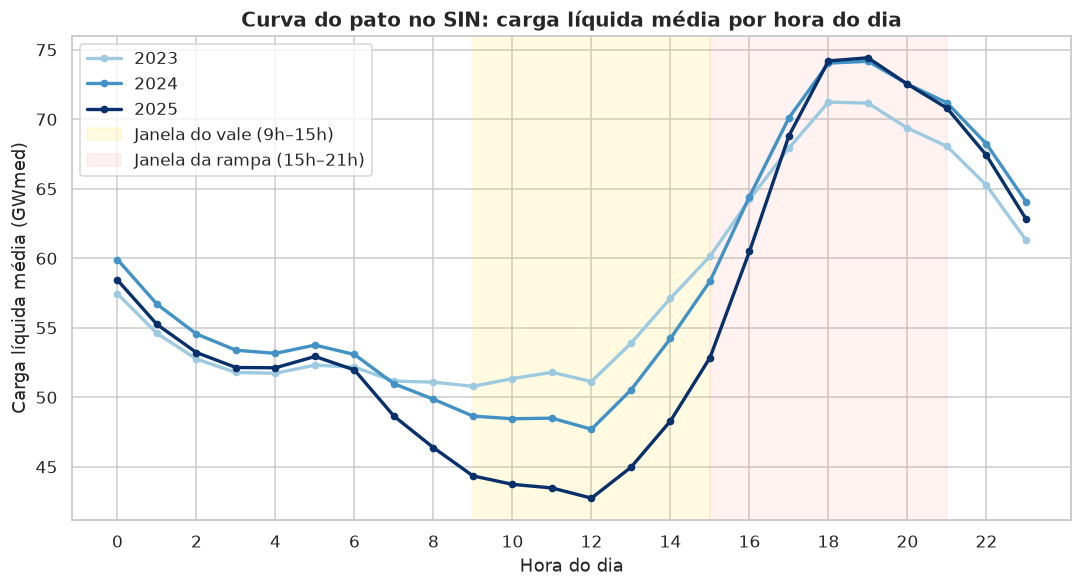

Carga líquida média (MWmed) – horas-chave:
ano      2023     2024     2025
hora                           
4     51730.0  53160.0  52121.0
12    51132.0  47701.0  42743.0
19    71159.0  74173.0  74422.0

Hora do vale por ano: {2023: 9, 2024: 12, 2025: 12}


In [9]:
perfil = sin.pivot_table(index="hora", columns="ano", values="carga_liquida", aggfunc="mean")

fig, ax = plt.subplots(figsize=(10, 5.5))
for ano in perfil.columns:
    ax.plot(perfil.index, perfil[ano] / 1000, marker="o", ms=4, lw=2.2, color=CORES[ano], label=str(ano))
ax.axvspan(9, 15, color="gold", alpha=0.12, label="Janela do vale (9h–15h)")
ax.axvspan(15, 21, color="tomato", alpha=0.08, label="Janela da rampa (15h–21h)")
ax.set_title("Curva do pato no SIN: carga líquida média por hora do dia", fontsize=13, weight="bold")
ax.set_xlabel("Hora do dia")
ax.set_ylabel("Carga líquida média (GWmed)")
ax.set_xticks(range(0, 24, 2))
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(PASTA_FIG / "fig1_curva_do_pato.png", dpi=150)
plt.show()

print("Carga líquida média (MWmed) – horas-chave:")
print(perfil.loc[[4, 12, 19]].round(0))
print("\nHora do vale por ano:", perfil.idxmin().to_dict())

### 5.3 Decomposição: carga bruta x solar no meio-dia e no início da noite

In [10]:
comp = sin[sin["hora"].isin([12, 19])].pivot_table(index="ano", columns="hora",
        values=["val_carga", "val_gersolar", "carga_liquida"], aggfunc="mean").round(0)
comp

carga_liquida          val_carga          val_gersolar      
hora            12       19        12       19           12    19
ano                                                              
2023       51132.0  71159.0   74043.0  82913.0      14747.0  20.0
2024       47701.0  74173.0   81440.0  87570.0      25079.0  23.0
2025       42743.0  74422.0   80598.0  89975.0      31118.0  21.0

### 5.4 Distribuição da rampa máxima diária (3h) por ano

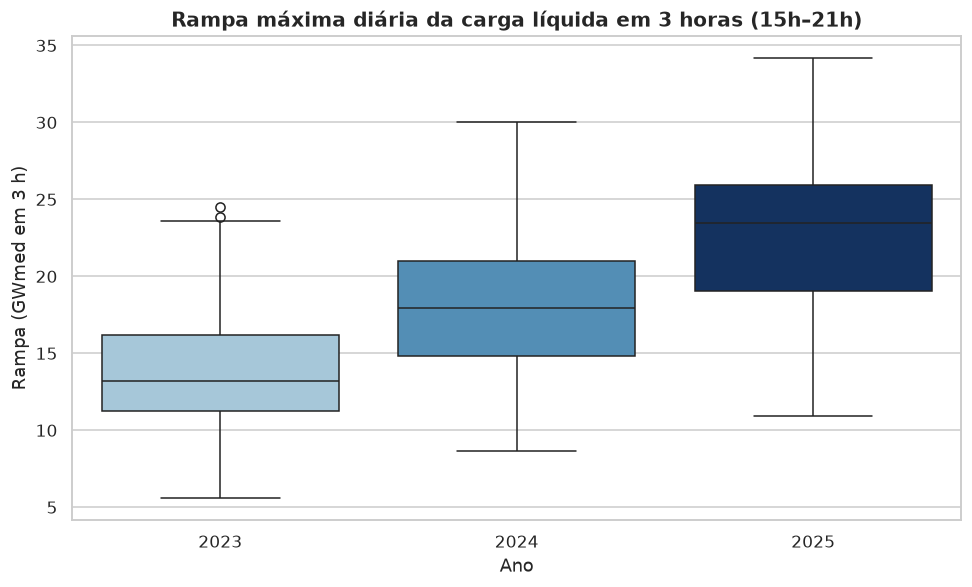

,rampa_max_3h,vale_meio_dia,pico_noite,amplitude,rampa_P95,rampa_max
ano,,,,,,
2023,13834.0,50177.0,72386.0,22209.0,21198.0,24471.0
2024,17835.0,47249.0,75286.0,28037.0,24999.0,30012.0
2025,22524.0,42584.0,75597.0,33013.0,29202.0,34196.0


In [11]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.boxplot(data=diario, x="ano", y=diario["rampa_max_3h"] / 1000, hue="ano",
            palette={a: CORES[a] for a in CORES}, legend=False, ax=ax)
ax.set_title("Rampa máxima diária da carga líquida em 3 horas (15h–21h)", fontsize=13, weight="bold")
ax.set_xlabel("Ano")
ax.set_ylabel("Rampa (GWmed em 3 h)")
plt.tight_layout()
plt.savefig(PASTA_FIG / "fig2_boxplot_rampa.png", dpi=150)
plt.show()

resumo = diario.groupby("ano")[["rampa_max_3h", "vale_meio_dia", "pico_noite", "amplitude"]].mean().round(0)
resumo["rampa_P95"] = diario.groupby("ano")["rampa_max_3h"].quantile(0.95).round(0)
resumo["rampa_max"] = diario.groupby("ano")["rampa_max_3h"].max().round(0)
resumo

### 5.5 Evolução mensal da amplitude (pico − vale)

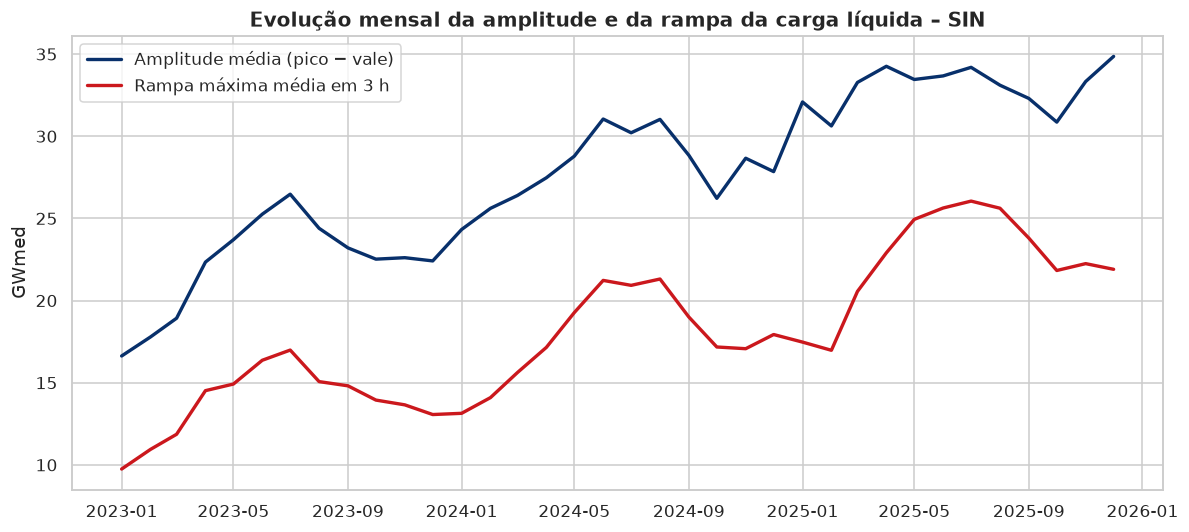

In [12]:
mensal = diario.resample("MS")[["amplitude", "rampa_max_3h"]].mean()

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(mensal.index, mensal["amplitude"] / 1000, lw=2.2, color="#08306b", label="Amplitude média (pico − vale)")
ax.plot(mensal.index, mensal["rampa_max_3h"] / 1000, lw=2.2, color="#cb181d", label="Rampa máxima média em 3 h")
ax.set_title("Evolução mensal da amplitude e da rampa da carga líquida – SIN", fontsize=13, weight="bold")
ax.set_ylabel("GWmed")
ax.legend()
plt.tight_layout()
plt.savefig(PASTA_FIG / "fig3_evolucao_mensal.png", dpi=150)
plt.show()

## 6. Validação estatística
**H0:** a rampa máxima diária tem a mesma distribuição nos três anos.
**H1:** ao menos um ano difere.

1. **Kruskal-Wallis** – não paramétrico, sem exigir normalidade.
2. **Regressão OLS** da rampa contra ano, com controle de mês (sazonalidade). Como dias consecutivos são autocorrelacionados, usam-se **erros-padrão HAC (Newey-West, 7 defasagens)**.

In [13]:
grupos = [g["rampa_max_3h"].values for _, g in diario.groupby("ano")]
h, p = stats.kruskal(*grupos)
print(f"Kruskal-Wallis: H = {h:,.1f} | p-valor = {p:.2e}")

# Normalidade (justifica o teste não paramétrico)
for ano, g in diario.groupby("ano"):
    print(f"Shapiro-Wilk {ano}: p = {stats.shapiro(g['rampa_max_3h']).pvalue:.2e}")

Kruskal-Wallis: H = 435.8 | p-valor = 2.30e-95
Shapiro-Wilk 2023: p = 2.76e-07
Shapiro-Wilk 2024: p = 2.09e-02
Shapiro-Wilk 2025: p = 5.77e-06


In [14]:
modelo = smf.ols("rampa_max_3h ~ C(ano) + C(mes)", data=diario).fit(
    cov_type="HAC", cov_kwds={"maxlags": 7})

efeitos = pd.DataFrame({
    "efeito_MWmed": modelo.params,
    "IC95_inf": modelo.conf_int()[0],
    "IC95_sup": modelo.conf_int()[1],
    "p_valor": modelo.pvalues,
}).filter(like="ano", axis=0).round(4)
print(f"R² = {modelo.rsquared:.3f}")
efeitos

R² = 0.595


,efeito_MWmed,IC95_inf,IC95_sup,p_valor
C(ano)[T.2024],4012.6112,3586.3323,4438.8900,0.0
C(ano)[T.2025],8690.6045,8224.1368,9157.0722,0.0


### 6.1 Verificação de robustez: a carga bruta explica a rampa?
Se o aumento da rampa viesse apenas do crescimento da carga, a rampa da **carga bruta** cresceria na mesma proporção.

In [15]:
sin["rampa_bruta_3h"] = sin["val_carga"].diff(3)
rb = sin[sin["hora"].between(15, 21)].groupby("data")["rampa_bruta_3h"].max()
comparacao = pd.DataFrame({
    "rampa_carga_bruta": rb.groupby(rb.index.year).mean(),
    "rampa_carga_liquida": diario.groupby("ano")["rampa_max_3h"].mean(),
}).round(0)
comparacao

,rampa_carga_bruta,rampa_carga_liquida
2023,7772.0,13834.0
2024,6599.0,17835.0
2025,8342.0,22524.0


## 7. Conclusões
- **Sim, o pato existe e se aprofundou a cada ano.** Em 2023 a carga líquida era quase plana entre a madrugada e o meio-dia; em 2025 formou-se um vale nítido às 12h (−8,4 GWmed), enquanto o pico das 19h subiu 3,3 GWmed.
- A **rampa média do fim de tarde cresceu cerca de 63%** entre 2023 e 2025, com significância estatística mesmo controlando a sazonalidade e a autocorrelação. A rampa da carga bruta praticamente não mudou (7,8 → 8,3 GWmed), o que indica que o crescimento vem da solar, não da carga.
- **Cenário real mais crítico:** a base não explicita a MMGD nem o *curtailment*. A MMGD reduz a carga verificada nas horas de sol e desaparece ao entardecer; o *curtailment* esconde parte da geração potencial no meio-dia. Os resultados devem ser lidos como **limite inferior** da necessidade de flexibilidade.

**Limitações:** análise associativa (não causal); carga também cresceu no período; apenas 3 anos; sem temperatura, hidrologia ou feriados.